<a href="https://colab.research.google.com/github/bookwork123/MachineLearning/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Imports**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN
from sklearn.metrics import silhouette_score, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import dendrogram, linkage

**Task 1: Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.**

The first code block loads the Wine dataset into a DataFrame. X holds the 13 features and y holds the cultivar of each wine.

The second block prints the number of rows and columns and the number of missing values in each column.

The third block shows summary statistics for each feature.

In the fourth block, I scale each feature to a mean of 0 and a standard deviation of 1 and store the result in a DataFrame.

The fifth block draws boxplots of each feature before and after scaling, side by side.

In [ ]:
wine = load_wine(as_frame=True)
X = wine.data
y = wine.target

In [ ]:
print(f"Dataset shape (samples, features): {X.shape}")
print(f"\nMissing values per feature:\n{X.isnull().sum()}")

Dataset shape (samples, features): (178, 13)

Missing values per feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64


In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

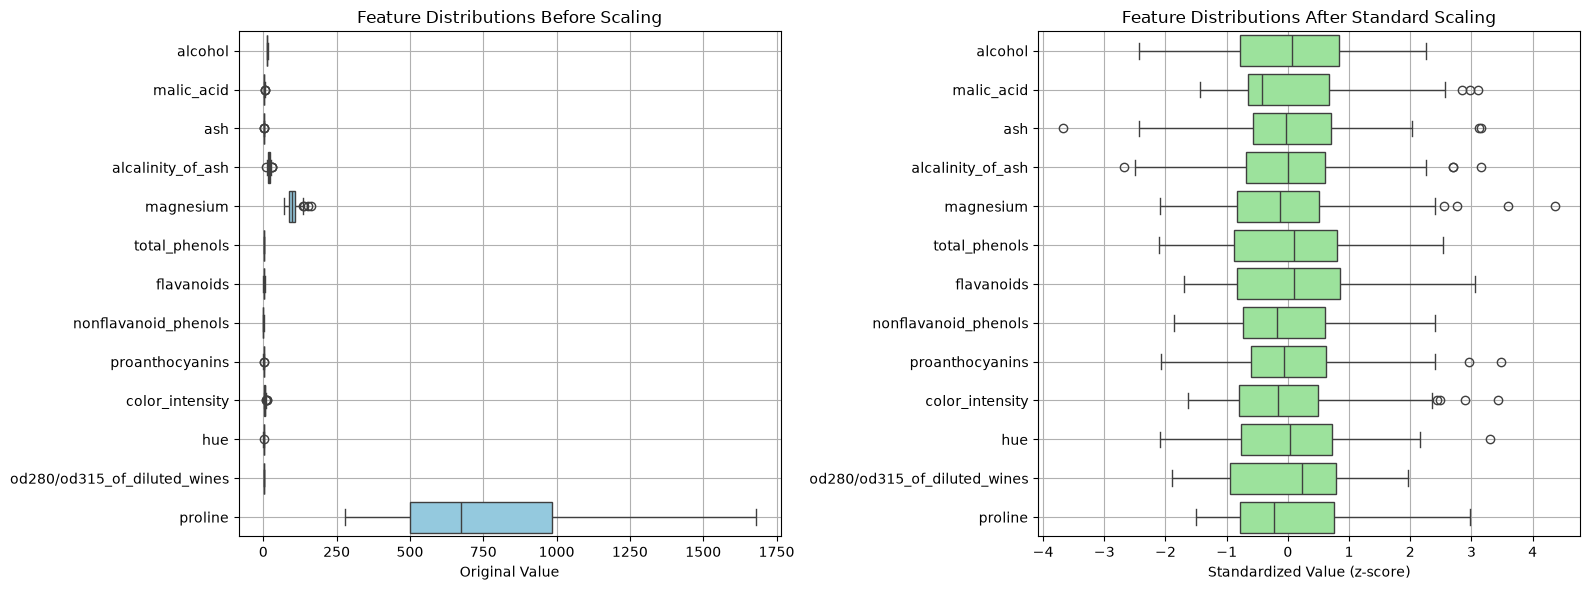

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=X, orient='h', ax=axes[0], color='skyblue')
axes[0].set_title('Feature Distributions Before Scaling')
axes[0].set_xlabel('Original Value')
axes[0].grid(True)

sns.boxplot(data=X_scaled_df, orient='h', ax=axes[1], color='lightgreen')
axes[1].set_title('Feature Distributions After Standard Scaling')
axes[1].set_xlabel('Standardized Value (z-score)')
axes[1].grid(True)

plt.tight_layout()
plt.show()

**Task 2: Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side: 1. The Elbow Method curve. 2. The Silhouette Scores curve for k in [2, 10]. Print the optimal k value suggested by both metrics.**

The first code block fits K-Means for each k from 1 to 10 and saves the inertia (the total squared distance from each point to its cluster center). For k from 2 to 10, it also saves the silhouette score.

The second block plots inertia against k (the elbow curve) and silhouette score against k, side by side.

The third block prints the optimal k for each metric.

In [ ]:
inertia = []
silhouette_scores = []
K_range = range(2, 11)

# Calculate inertia for k from 1 to 10
for k in range(1, 11):
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(X_scaled)
    inertia.append(kmeans_temp.inertia_)

# Calculate silhouette score for k from 2 to 10
for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans_temp.fit_predict(X_scaled)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

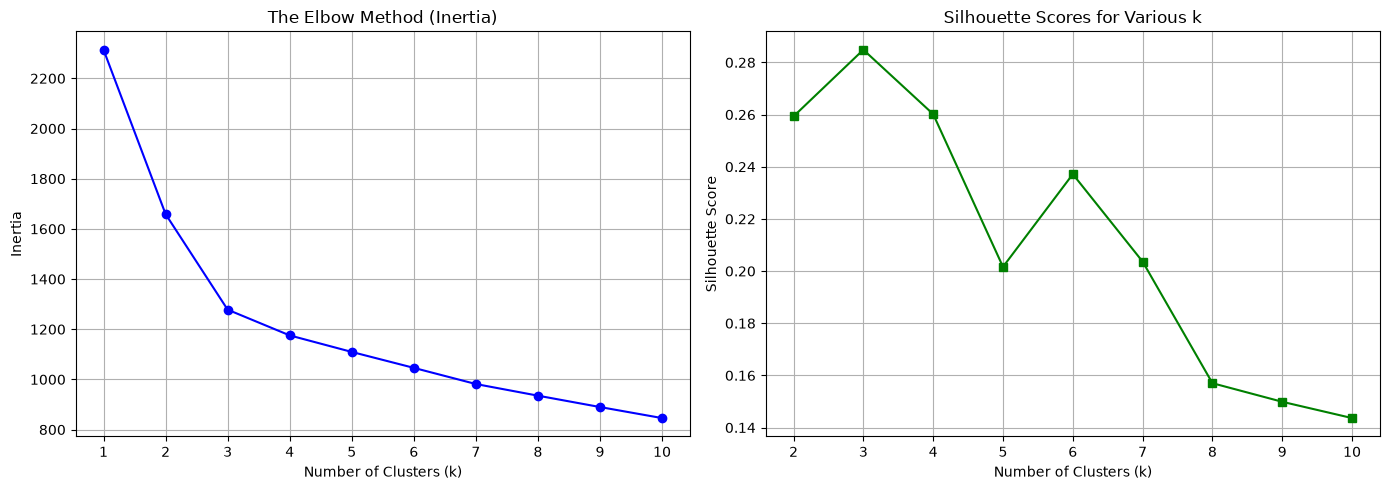

In [ ]:
# Plotting Elbow Method and Silhouette Scores side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Method Plot
ax1.plot(range(1, 11), inertia, marker='o', color='b', linestyle='-')
ax1.set_title('The Elbow Method (Inertia)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_xticks(range(1, 11))
ax1.grid(True)

# Silhouette Score Plot
ax2.plot(K_range, silhouette_scores, marker='s', color='g', linestyle='-')
ax2.set_title('Silhouette Scores for Various k')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_xticks(K_range)
ax2.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
print("Optimal k suggested by the Elbow Method: 3")
print("Optimal k suggested by the Silhouette Score: 3")

Optimal k suggested by the Elbow Method: 3
Optimal k suggested by the Silhouette Score: 3


**Task 3: Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the Voronoi method.**

The first code block reduces the 13 scaled features to 2 with PCA and stores them in X_pca.

The second block fits K-Means with k=3 on X_pca.

The third block defines three plotting functions and uses them to draw the cluster regions. plot_decision_boundaries predicts the cluster for every point on a fine grid and colors the plot by those predictions, so each region holds the points closest to one cluster center. plot_data draws the wines colored by cluster, and plot_centroids marks the cluster centers.

In [ ]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

In [ ]:
kmeans_2d = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_pca)

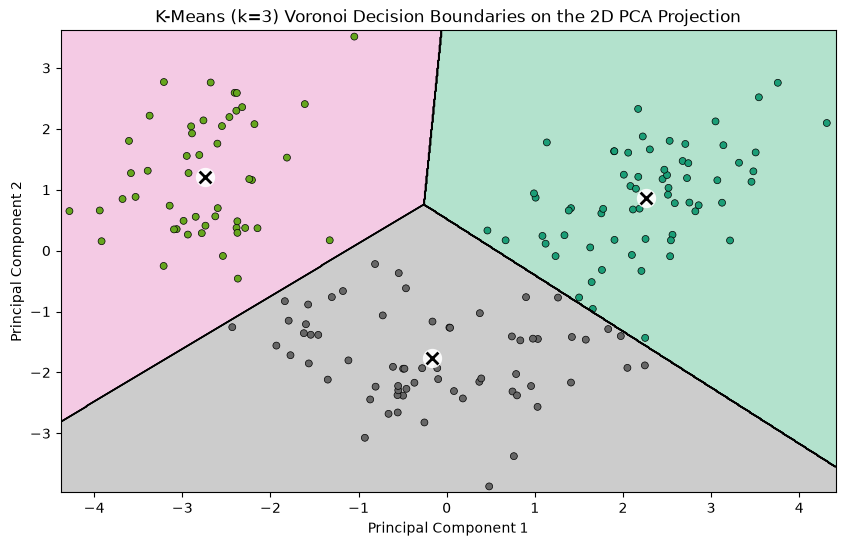

In [ ]:
def plot_data(X, labels):
    plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='Dark2', s=25, edgecolor='k', linewidths=0.5)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X, clusterer.predict(X))
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("Principal Component 1")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("Principal Component 2")
    else:
        plt.tick_params(labelleft=False)

plt.figure(figsize=(10, 6))
plot_decision_boundaries(kmeans_2d, X_pca)
plt.title('K-Means (k=3) Voronoi Decision Boundaries on the 2D PCA Projection')
plt.show()

**Task 4: Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.**

The first code block fits K-Means with k=3 on all 13 scaled features.

The second block selects 5 wines (rows 0, 40, 75, 110, and 150), computes each one's distance to the 3 cluster centers, and gets the cluster each one is assigned to.

The third block draws the distances as a heatmap, with one row per wine and one column per cluster center, and outlines the smallest distance in each row in red.

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

In [ ]:
sample_indices = [0, 40, 75, 110, 150]
X_samples = X_scaled[sample_indices]

# Compute distances from each sample to all 3 centroids (soft clustering)
distances = kmeans.transform(X_samples)

# Hard clustering prediction for these samples
sample_predictions = kmeans.predict(X_samples)

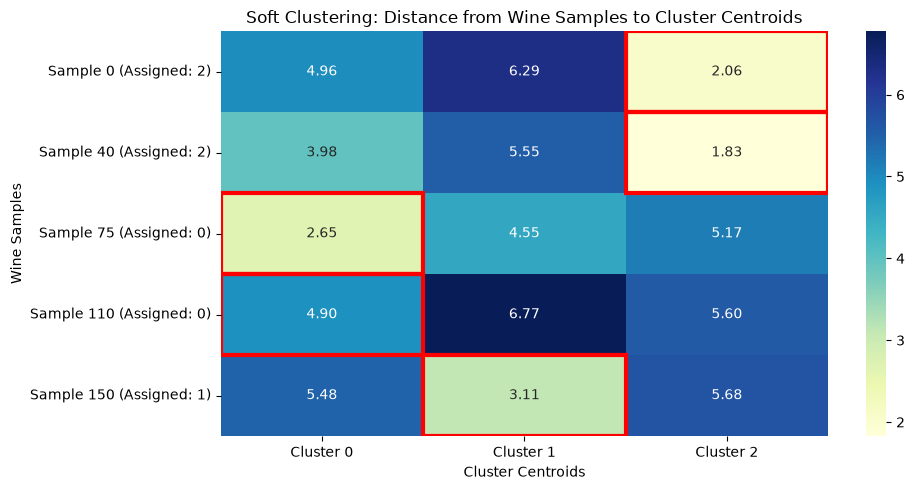

In [ ]:
# Visualize distances using a heatmap
plt.figure(figsize=(10, 5))
ax = sns.heatmap(
    distances,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=[f"Cluster {i}" for i in range(3)],
    yticklabels=[f"Sample {idx} (Assigned: {pred})" for idx, pred in zip(sample_indices, sample_predictions)]
)

# Highlight the minimum distance (hard cluster assignment) in each row
for row, col in enumerate(np.argmin(distances, axis=1)):
    ax.add_patch(patches.Rectangle((col, row), 1, 1, fill=False, edgecolor='red', linewidth=3))

plt.title("Soft Clustering: Distance from Wine Samples to Cluster Centroids")
plt.xlabel("Cluster Centroids")
plt.ylabel("Wine Samples")
plt.tight_layout()
plt.show()

**Task 5: Fit a DBSCAN model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.**

DBSCAN takes two settings: eps, the radius around each point, and min_samples, the number of points needed within that radius for a point to be a core point.

The first code block fits DBSCAN on the 13 scaled features with three combinations of eps and min_samples and prints the number of clusters and noise points for each.

The second block fits the final model with eps=2.3 and min_samples=3 and prints its number of clusters and noise points.

The third block defines plot_dbscan, which splits the wines into core points, border points (cluster members that are not core points), and noise, and draws them on the 2D PCA projection from Task 3. Core points are large circles, border points are small dots, and noise points are red x's.

In [ ]:
for eps, min_samples in [(2.0, 5), (2.3, 3), (2.5, 5)]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)

    # Count clusters and noise points (-1 represents noise points)
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise_ = list(labels).count(-1)

    print(f"eps={eps}, min_samples={min_samples}: {n_clusters_} clusters, {n_noise_} noise points")

eps=2.0, min_samples=5: 5 clusters, 85 noise points
eps=2.3, min_samples=3: 3 clusters, 32 noise points
eps=2.5, min_samples=5: 1 clusters, 24 noise points


In [ ]:
# Instantiate and fit DBSCAN on scaled features
dbscan = DBSCAN(eps=2.3, min_samples=3)
dbscan_labels = dbscan.fit_predict(X_scaled)

# Count clusters and noise points (-1 represents noise points)
n_clusters_ = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise_ = list(dbscan_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters_}")
print(f"Estimated number of noise points: {n_noise_}")

Estimated number of clusters: 3
Estimated number of noise points: 32


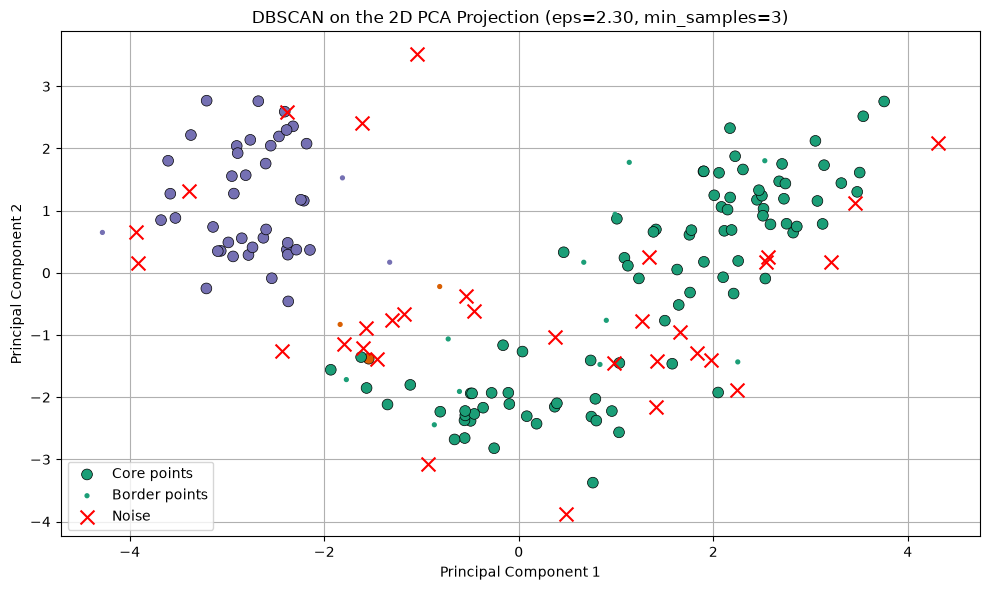

In [ ]:
def plot_dbscan(dbscan, X, size, show_xlabels=True, show_ylabels=True):
    core_mask = np.zeros_like(dbscan.labels_, dtype=bool)
    core_mask[dbscan.core_sample_indices_] = True
    anomalies_mask = dbscan.labels_ == -1
    non_core_mask = ~(core_mask | anomalies_mask)

    # X is the 2D PCA projection, so the core points are taken from X instead of dbscan.components_ (13D)
    cores = X[core_mask]
    anomalies = X[anomalies_mask]
    non_cores = X[non_core_mask]

    plt.scatter(cores[:, 0], cores[:, 1],
                c=dbscan.labels_[core_mask], marker='o', s=size, cmap="Dark2",
                vmin=0, vmax=7, edgecolor='k', linewidths=0.5, label='Core points')
    plt.scatter(non_cores[:, 0], non_cores[:, 1],
                c=dbscan.labels_[non_core_mask], marker=".", s=size / 2, cmap="Dark2",
                vmin=0, vmax=7, label='Border points')
    plt.scatter(anomalies[:, 0], anomalies[:, 1],
                c="r", marker="x", s=100, label='Noise')
    if show_xlabels:
        plt.xlabel("Principal Component 1")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("Principal Component 2")
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"DBSCAN on the 2D PCA Projection (eps={dbscan.eps:.2f}, min_samples={dbscan.min_samples})")
    plt.legend(loc='lower left')
    plt.grid()
    plt.gca().set_axisbelow(True)

plt.figure(figsize=(10, 6))
plot_dbscan(dbscan, X_pca, size=60)
plt.tight_layout()
plt.show()

**Task 6: Fit an `HDBSCAN` model (using `min_cluster_size=5` or `min_samples=5`) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.**

The first code block fits HDBSCAN with min_cluster_size=5 on the 13 scaled features and prints the number of clusters and noise points.

The second block puts the 2D PCA projection from Task 3 and the HDBSCAN labels into a DataFrame, then plots each wine colored by its cluster.

In [ ]:
# Instantiate and fit HDBSCAN on scaled features
hdbscan_model = HDBSCAN(min_cluster_size=5, copy=True)
hdbscan_labels = hdbscan_model.fit_predict(X_scaled)

# Count clusters and noise points (-1 represents noise points)
n_hdbscan_clusters_ = len(set(hdbscan_labels)) - (1 if -1 in hdbscan_labels else 0)
n_hdbscan_noise_ = list(hdbscan_labels).count(-1)

print(f"Estimated number of HDBSCAN clusters: {n_hdbscan_clusters_}")
print(f"Estimated number of HDBSCAN noise points: {n_hdbscan_noise_}")

Estimated number of HDBSCAN clusters: 2
Estimated number of HDBSCAN noise points: 58


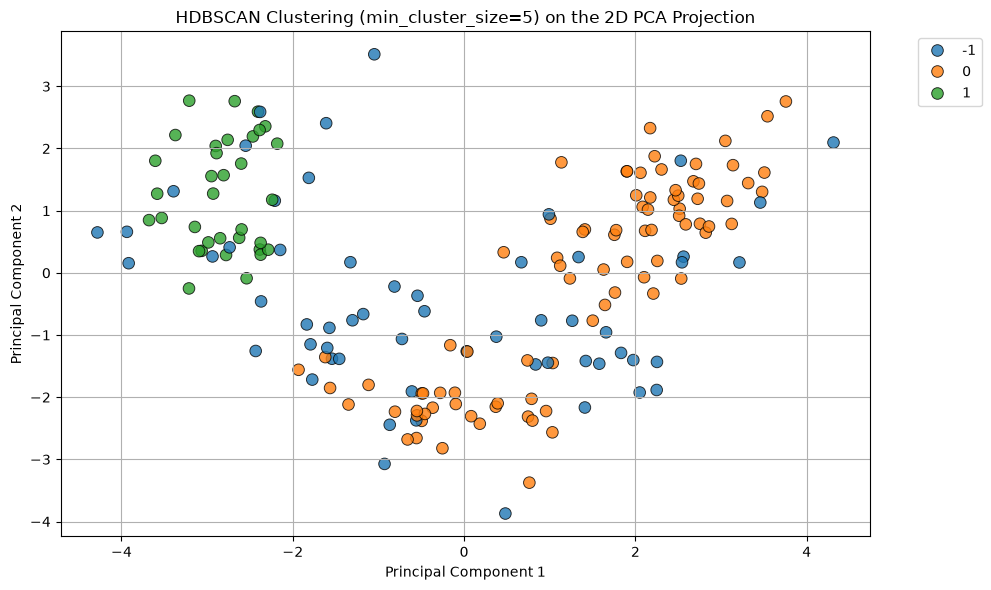

In [ ]:
df_pca = pd.DataFrame(X_pca, columns=['Principal Component 1', 'Principal Component 2'])

# Add HDBSCAN labels to the dataframe
df_pca['HDBSCAN_Cluster'] = hdbscan_labels

# Visualize HDBSCAN clustering results
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Principal Component 1',
    y='Principal Component 2',
    hue='HDBSCAN_Cluster',
    data=df_pca,
    palette='tab10',
    s=70,
    alpha=0.8,
    edgecolor='k',
    legend='full'
)
plt.title('HDBSCAN Clustering (min_cluster_size=5) on the 2D PCA Projection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

**Task 7: Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.**

The first code block builds a single-linkage tree from the 13 scaled features. Single linkage repeatedly joins the two groups whose closest points are nearest to each other.

The second block draws the tree as a dendrogram. Each wine starts as a leaf at the bottom, and the height where two branches join is the distance at which they merge. HDBSCAN builds a similar tree and keeps the branches that stay together over the widest range of heights as its clusters.

In [ ]:
# Compute the linkage matrix using single linkage on scaled data
# to illustrate the hierarchical tree structure
linked = linkage(X_scaled, method='single')

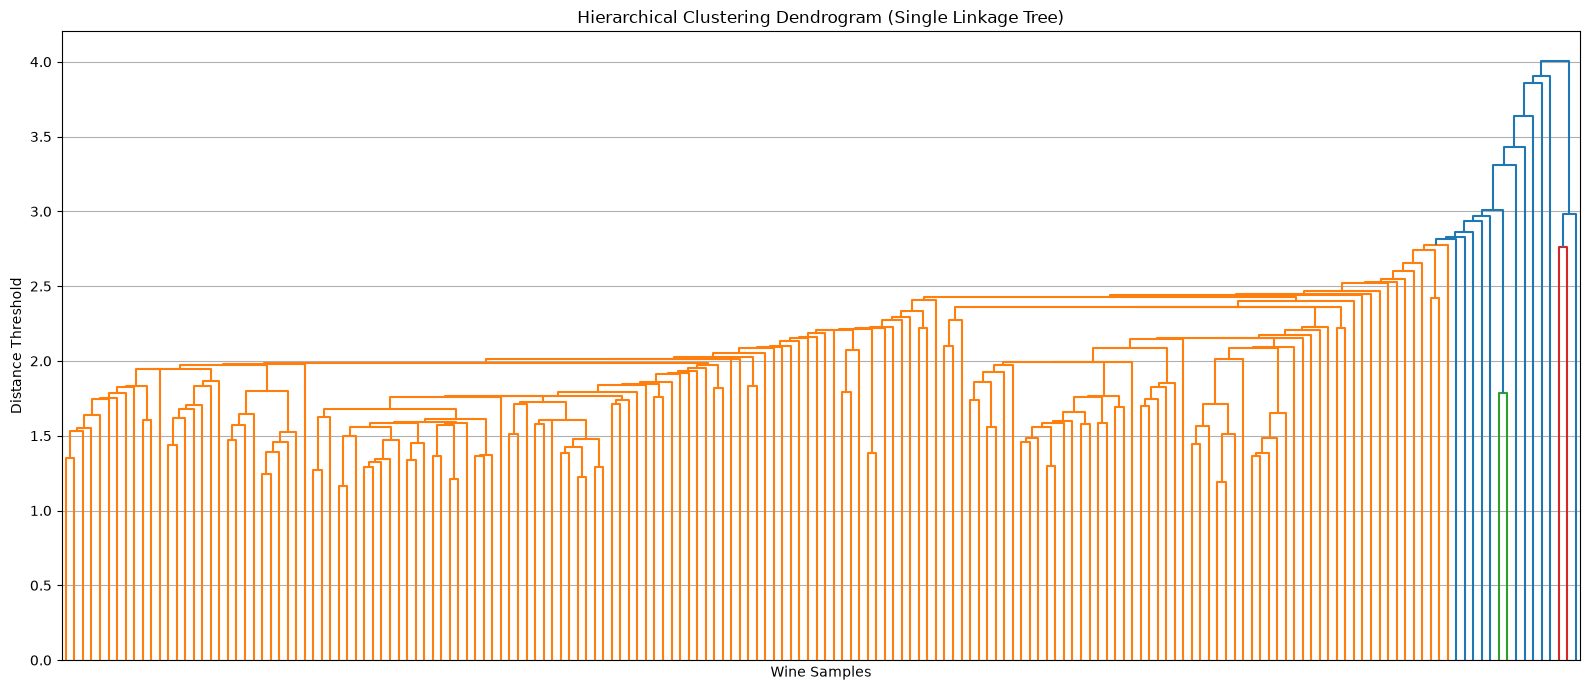

In [ ]:
plt.figure(figsize=(16, 7))
dendrogram(
    linked,
    orientation='top',
    distance_sort='descending',
    show_leaf_counts=False,
    no_labels=True
)

plt.title('Hierarchical Clustering Dendrogram (Single Linkage Tree)')
plt.xlabel('Wine Samples')
plt.ylabel('Distance Threshold')
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Task 8: Treat the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a Random Forest or Logistic Regression using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). Plot the classification accuracy and Silhouette Scores for all three algorithms.**

The first code block collects the cluster labels from K-Means (Task 4), DBSCAN (Task 5), and HDBSCAN (Task 6).

The second block splits the row numbers 80/20 into training and test sets, keeping the same share of each cultivar in both.

The third block repeats the following for each algorithm: it turns each cluster label into its own 0/1 column, trains a Random Forest on those columns to predict the cultivar, and records the test accuracy. It also computes the silhouette score on the 13 scaled features, leaving out noise points (label -1).

The fourth block plots accuracy on the left axis and silhouette score on the right axis for each algorithm.

In [ ]:
cluster_labels = {
    'K-Means (k=3)': kmeans_labels,
    'DBSCAN': dbscan_labels,
    'HDBSCAN': hdbscan_labels,
}

In [ ]:
indices = np.arange(len(y))
train_idx, test_idx, y_train, y_test = train_test_split(
    indices, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
accuracies = []
silhouettes = []

for name, labels in cluster_labels.items():
    # One-hot encode the cluster labels so they are treated as categories
    encoder = OneHotEncoder(handle_unknown='ignore')
    X_clusters = encoder.fit_transform(labels.reshape(-1, 1))

    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_clusters[train_idx], y_train)
    acc = accuracy_score(y_test, clf.predict(X_clusters[test_idx]))
    accuracies.append(acc)

    # Silhouette score on the 13 scaled features, leaving out noise points (-1)
    mask = labels != -1
    sil = silhouette_score(X_scaled[mask], labels[mask])
    silhouettes.append(sil)

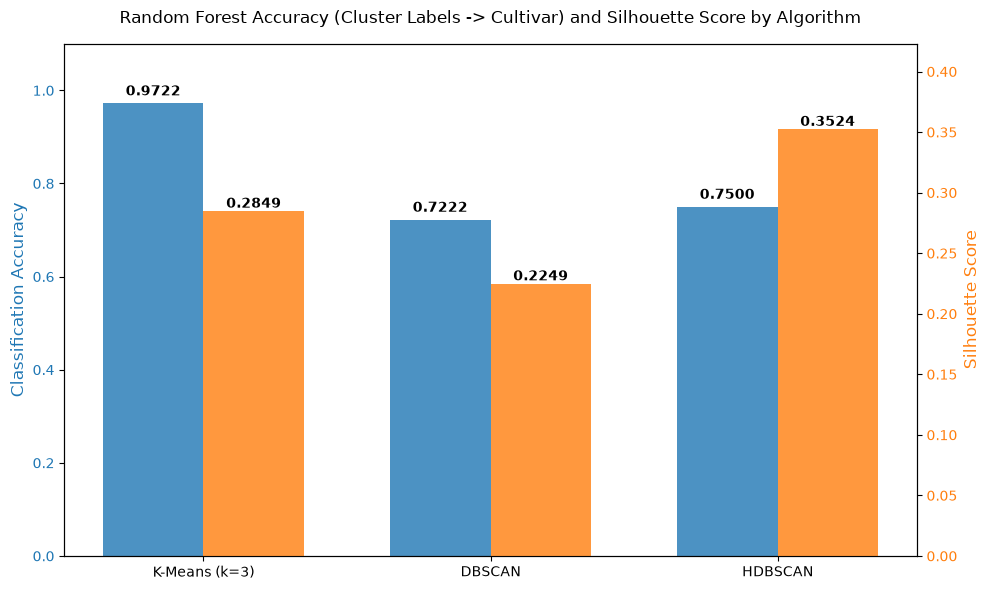

In [ ]:
models = list(cluster_labels.keys())

x = np.arange(len(models))
width = 0.35

fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Accuracy bars on primary y-axis
color = 'tab:blue'
ax1.set_ylabel('Classification Accuracy', color=color, fontsize=12)
bars1 = ax1.bar(x - width/2, accuracies, width, label='Accuracy', color=color, alpha=0.8)
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, 1.1)

# Instantiate secondary axis for silhouette score
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=12)
bars2 = ax2.bar(x + width/2, silhouettes, width, label='Silhouette Score', color=color, alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max(silhouettes) * 1.2)

# Annotate values on top of each bar
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, f"{yval:.4f}",
             ha="center", va="bottom", fontsize=10, fontweight="bold")
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, yval, f"{yval:.4f}",
             ha="center", va="bottom", fontsize=10, fontweight="bold")

# Formatting
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=10)
plt.title('Random Forest Accuracy (Cluster Labels -> Cultivar) and Silhouette Score by Algorithm', fontsize=12, pad=15)
fig.tight_layout()
plt.show()